# 2D visibility: visibility polygons, isovist metrics and catchment zones

`get_visibility` computes the exact visibility polygon (isovist) of each observer within a viewing radius; obstacles
are walls of infinite height. This notebook shows

1. the visibility polygon of one observer and of several observers with individual radii;
2. isovist metrics (`isovist_metrics=True`) mapped over a dense set of observers;
3. visibility catchment zones (`get_visibility_catchment`).

2.5D viewsheds over building heights are covered in the [viewshed notebook](viewshed.ipynb).

In [1]:
# !pip install objectnat pyarrow matplotlib

In [2]:
import geopandas as gpd
import shapely
from shapely.geometry import Point

from objectnat import get_visibility, get_visibility_catchment

obstacles = gpd.read_parquet("examples_data/buildings.parquet")  # EPSG:32636, metres

In [3]:
import matplotlib.pyplot as plt
import numpy as np


def map_axes(ax, bounds, step=100):
    """Show `bounds` (x0, y0, x1, y1 in metres) with axes in metres from the lower-left corner."""
    x0, y0, x1, y1 = bounds
    ax.set_xlim(x0, x1)
    ax.set_ylim(y0, y1)
    ax.set_aspect("equal")
    ax.set_xticks(x0 + np.arange(0, x1 - x0 + 1, step), [f"{v:g}" for v in np.arange(0, x1 - x0 + 1, step)])
    ax.set_yticks(y0 + np.arange(0, y1 - y0 + 1, step), [f"{v:g}" for v in np.arange(0, y1 - y0 + 1, step)])
    ax.set_xlabel("x, m")
    ax.set_ylabel("y, m")
    ax.tick_params(labelsize=8)
from matplotlib.patches import Patch

## 1. One observer

Observers may be in any CRS; the calculation runs in an estimated UTM zone and the result is returned in the CRS of
the observers.

visible area 39.0 ha of 201.1 ha


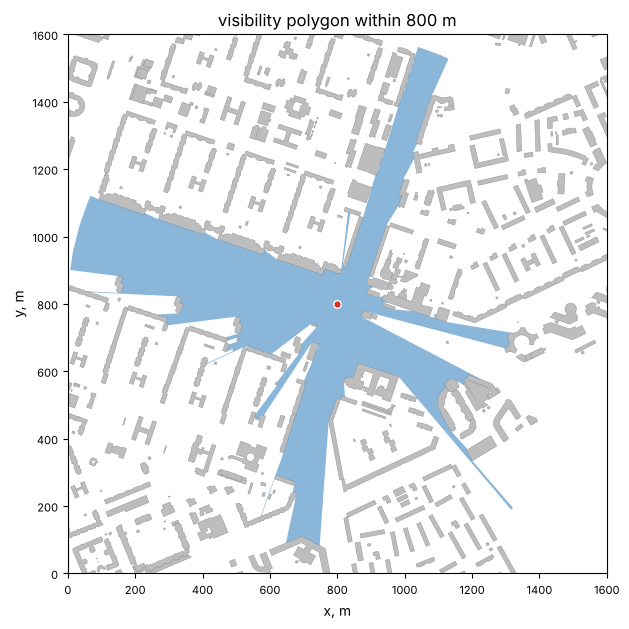

In [4]:
observer = gpd.GeoDataFrame(geometry=[Point(30.2312112, 59.9482336)], crs=4326)
visible = get_visibility(observer, obstacles, view_distance=800)
local = visible.to_crs(obstacles.crs)
print(f"visible area {local.area.iloc[0] / 1e4:.1f} ha of {3.14159 * 800 ** 2 / 1e4:.1f} ha")

c = observer.to_crs(obstacles.crs).geometry.iloc[0]
bounds = (c.x - 800, c.y - 800, c.x + 800, c.y + 800)
fig, ax = plt.subplots(figsize=(7, 7))
obstacles.plot(ax=ax, color="#bdbdbd", edgecolor="#8c8c8c", linewidth=0.3)
local.plot(ax=ax, color="#2b7bba", alpha=0.55, linewidth=0)
observer.to_crs(obstacles.crs).plot(ax=ax, color="#d7301f", markersize=30, edgecolor="white")
map_axes(ax, bounds, step=200)
ax.set_title("visibility polygon within 800 m")
plt.show()

## 2. Several observers

A `visibility_distance` column sets the radius of every observer (metres). Observers are processed in parallel by
the Rust extension; observers inside an obstacle get an empty polygon.

In [5]:
points = gpd.GeoDataFrame(
    {"visibility_distance": [300, 500, 800]},
    geometry=[Point(30.2312112, 59.9482336), Point(30.2390, 59.9465), Point(30.2250, 59.9500)],
    crs=4326,
)
many = get_visibility(points, obstacles)
many.to_crs(obstacles.crs).assign(area_ha=lambda g: g.area / 1e4)[["visibility_distance", "area_ha"]].round(2)

,visibility_distance,area_ha
0,300,15.54
1,500,21.70
2,800,1.87


## 3. Isovist metrics

`isovist_metrics=True` adds `area`, `perimeter`, `compactness` (4πA/P²), `occlusivity` and `n_occlusions`,
radial statistics (`min_radial`, `max_radial`, `mean_radial`, `std_radial`, `skew_radial`), `drift` (distance from
the observer to the centroid of the polygon), `view_share` and `open_share`. Lengths are in metres. Here observers
are placed every 6 m on the open ground of a 500 × 500 m square.

In [6]:
import numpy as np

centre = (346050, 6647450)
square = shapely.box(centre[0] - 250, centre[1] - 250, centre[0] + 250, centre[1] + 250)
scene = obstacles[obstacles.intersects(square.buffer(200))]
xx, yy = np.meshgrid(np.arange(square.bounds[0] + 3, square.bounds[2], 6), np.arange(square.bounds[1] + 3, square.bounds[3], 6))
grid = shapely.points(xx.ravel(), yy.ravel())
grid = grid[~shapely.intersects(shapely.union_all(scene.geometry.values).buffer(0.5), grid)]
observers = gpd.GeoDataFrame(geometry=grid, crs=obstacles.crs)

isovists = get_visibility(observers, scene, view_distance=200, isovist_metrics=True)
print(len(isovists), "isovists")
isovists.drop(columns="geometry").describe().T[["mean", "min", "50%", "max"]].round(2)

5328 isovists


,mean,min,50%,max
area,26614.54,1381.04,19704.85,70468.91
perimeter,1481.15,195.46,1500.86,2723.55
compactness,0.15,0.03,0.13,0.49
occlusivity,817.44,74.12,793.09,1819.06
n_occlusions,17.35,3.00,17.00,36.00
min_radial,15.08,0.51,11.69,77.83
max_radial,196.98,58.60,200.00,200.00
mean_radial,68.93,10.35,60.59,141.51
std_radial,51.54,12.68,50.35,90.77
skew_radial,1.15,-0.51,1.19,5.43


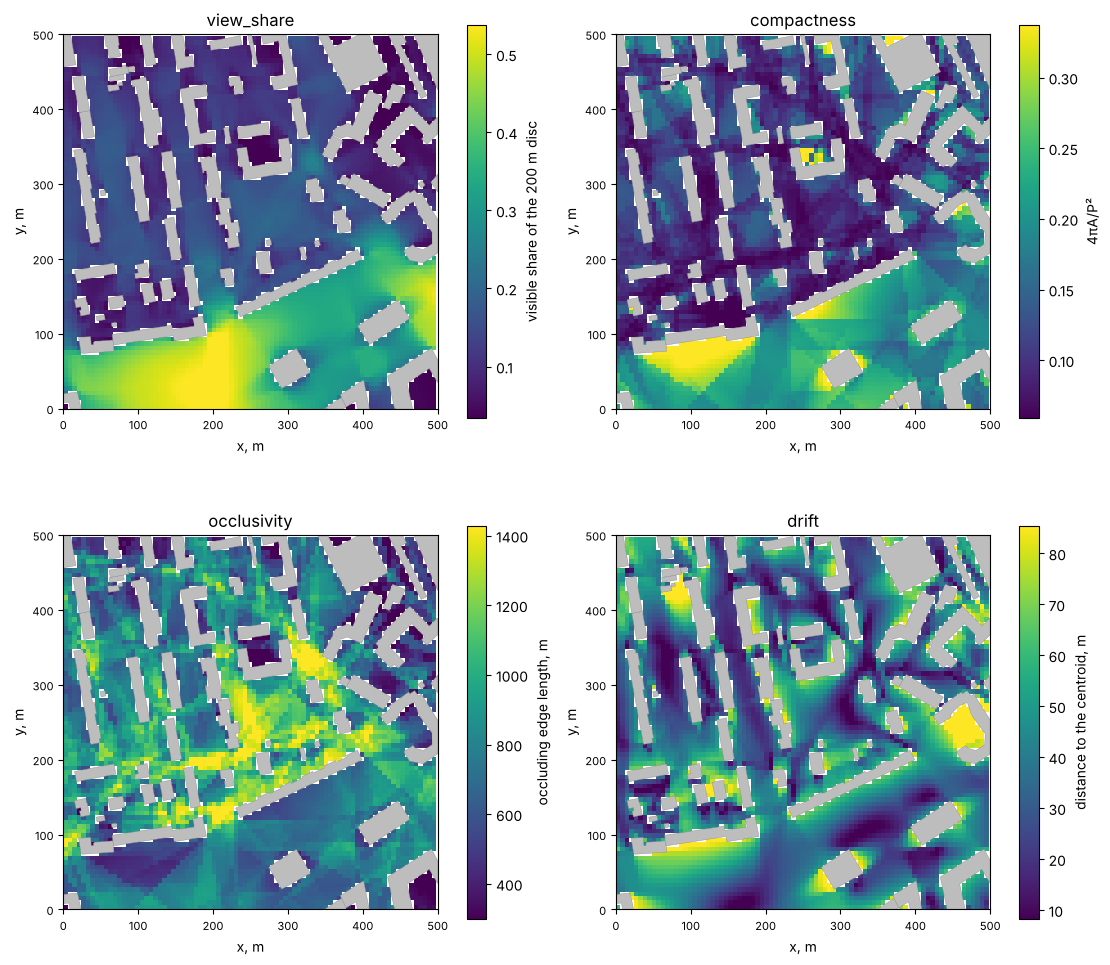

In [7]:
def raster(ax, points, values, step, **kw):
    xy = shapely.get_coordinates(points)
    i = np.round((xy[:, 0] - xy[:, 0].min()) / step).astype(int)
    j = np.round((xy[:, 1] - xy[:, 1].min()) / step).astype(int)
    img = np.full((j.max() + 1, i.max() + 1), np.nan)
    img[j, i] = values
    x0, y0 = xy[:, 0].min() - step / 2, xy[:, 1].min() - step / 2
    return ax.imshow(img, origin="lower", extent=(x0, x0 + img.shape[1] * step, y0, y0 + img.shape[0] * step),
                     interpolation="nearest", **kw)


fig, axs = plt.subplots(2, 2, figsize=(11, 10), constrained_layout=True)
for ax, (col, label) in zip(axs.ravel(), [
    ("view_share", "visible share of the 200 m disc"),
    ("compactness", "4πA/P²"),
    ("occlusivity", "occluding edge length, m"),
    ("drift", "distance to the centroid, m"),
]):
    vals = isovists[col].to_numpy()
    lo, hi = np.nanpercentile(vals, [2, 98])
    im = raster(ax, observers.geometry.values, vals, 6.0, cmap="viridis", vmin=lo, vmax=hi)
    scene.clip(square).plot(ax=ax, color="#bdbdbd", edgecolor="#8c8c8c", linewidth=0.3)
    map_axes(ax, square.bounds)
    ax.set_title(col)
    fig.colorbar(im, ax=ax, shrink=0.8, label=label)
plt.show()

Open squares and wide streets have a high `view_share` and `compactness`; narrow yards have a low `view_share`; the
`occlusivity` is high where many building corners hide space close to the observer, and `drift` is high near walls
that face an open area.

## 4. Visibility catchment zones

`get_visibility_catchment` counts, for every `cell_size` cell, the observers whose visibility polygon contains the
cell centre and merges cells into classes. Observers along streets usually come from
`get_observer_points(urban_graph, spacing=15)`; for example, with a walk graph from IduEdu:

```python
from iduedu import config, download_osm_pbf, get_walk_graph
from objectnat import get_observer_points

pbf = download_osm_pbf(osm_id=1114252, region="northwestern-fed-district")
with config.use_pbf(pbf):
    walk = get_walk_graph(osm_id=1114252)
observers = get_observer_points(walk, spacing=15)
```

Here, to stay independent of downloads, observers are placed every 15 m on open ground within 12 m of a building.

In [8]:
footprints = shapely.union_all(scene.geometry.values)
xx, yy = np.meshgrid(np.arange(square.bounds[0], square.bounds[2], 15), np.arange(square.bounds[1], square.bounds[3], 15))
pts = shapely.points(xx.ravel(), yy.ravel())
pts = pts[~shapely.intersects(footprints.buffer(2), pts) & shapely.intersects(footprints.buffer(12), pts)]
street_observers = gpd.GeoDataFrame(geometry=pts, crs=obstacles.crs)

quantile_zones = get_visibility_catchment(street_observers, scene, view_distance=250, cell_size=4, classes=5)
fixed_zones = get_visibility_catchment(street_observers, scene, view_distance=250, cell_size=4, classes=[1, 10, 25, 50])
print(len(street_observers), "observers")
quantile_zones.drop(columns="geometry")

398 observers


,visibility_class,count_min,count_max
0,1,1,3
1,2,4,10
2,3,11,22
3,4,23,36
4,5,37,73


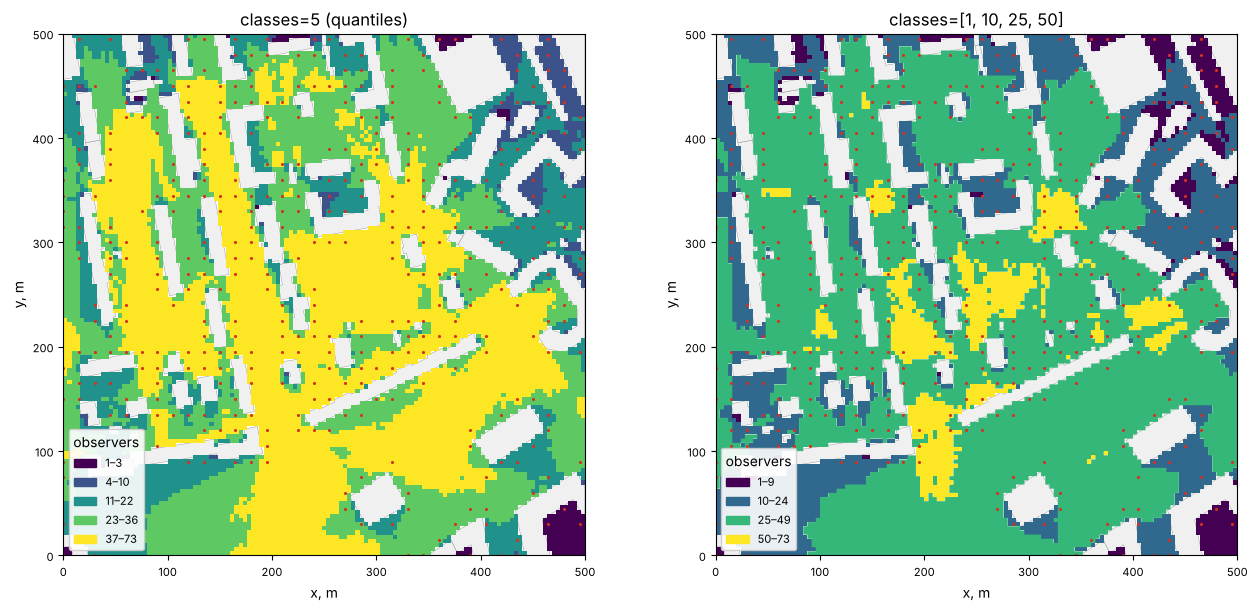

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(13, 6), constrained_layout=True)
for ax, zones, title in [(axs[0], quantile_zones, "classes=5 (quantiles)"), (axs[1], fixed_zones, "classes=[1, 10, 25, 50]")]:
    cmap = plt.get_cmap("viridis", len(zones))
    scene.clip(square).plot(ax=ax, color="#f0f0f0", edgecolor="#8c8c8c", linewidth=0.3)
    zones.plot(ax=ax, color=[cmap(k) for k in range(len(zones))], linewidth=0)
    street_observers.plot(ax=ax, color="#d7301f", markersize=1.5)
    map_axes(ax, square.bounds)
    labels = [f"{lo}–{hi}" for lo, hi in zip(zones["count_min"], zones["count_max"])]
    ax.legend(handles=[Patch(color=cmap(k), label=lab) for k, lab in enumerate(labels)], title="observers",
              loc="lower left", fontsize=8, framealpha=0.9)
    ax.set_title(title)
plt.show()

Quantile classes adapt to the data and are comparable only within one run; explicit bounds give the same scale for
different areas or scenarios. `weight_column` replaces counts by sums of observer weights, for example pedestrian
flow.